# Numerical experiments: reproducing the paper's figures

This notebook runs the sliding-bar simulation used throughout the paper
and reproduces every computed figure of the paper and of its
supplementary material, using the modules in this directory
(`inductance.py`, `dynamics.py`, `models.py`, `figures.py`): the two
trajectory panels of the paper's regimes figure, its $\varepsilon$
signatures figure, and the two self-inductance figures of the
supplementary material. The paper's two schematic diagrams -- the circuit
itself, and the field of a current element -- are hand drawn rather than
computed, so they have no cell here.

**Runtime.** With `numba` installed the notebook runs at
`FULL_RESOLUTION = True` (the default whenever `numba` is available), which
uses the paper's exact parameters and step counts, in about 35 s, and
saves every figure to `figures/` under the file name the paper and the
supplement use. `FULL_RESOLUTION = False` is a fast demo (about 10 s) that
does not save anything. Without `numba` the closed-form self-inductance
is evaluated in pure Python several times per integration step -- about
150 s per million steps -- so the same two runs take roughly 20 and 45
minutes instead (`pip install numba`, no compiler needed; see `_jit.py` and
`requirements.txt`), which is why the default falls back to the fast demo
without it. The reduced default does not switch off `numba`; it
only lowers the step counts of the two trajectory figures and the number of
$\varepsilon$ values swept for the last one.


In [1]:
import sys, time
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt

import _jit
import inductance, dynamics, models, figures

print("numba available:", _jit.HAVE_NUMBA,
      "-- simulations will run" if _jit.HAVE_NUMBA else "-- WARNING: numba not found, simulations will run",
      "~150x slower without it (still correct, just slow); see requirements.txt.")


numba available: True -- simulations will run ~150x slower without it (still correct, just slow); see requirements.txt.


## Configuration

`FULL_RESOLUTION = True` reproduces the paper's figures exactly (the
paper's own step counts) and writes them to `figures/`; it is the default
when `numba` is installed. Set it to `False` for a fast demo run, which
shows truncated trajectories and saves nothing.
Physical parameters below (`l`, `x0`, `p0`, `mu`, `dt`) match the paper's
Section "Results" defaults in every case; only the number of integration
steps changes with this flag.


In [2]:
import os

FULL_RESOLUTION = _jit.HAVE_NUMBA  # True reproduces (and saves) the paper's figures exactly

# Paper defaults, Section "Results": mu0=1, l=100, x0=500, p0=-1e-2, dt=2e-4
l, x0, p0, mu, dt, rho = 100.0, 500.0, -1.e-2, 1.0, 2.e-4, 1.0

N_NORMAL = 4_000_000 if FULL_RESOLUTION else 200_000   # over-damped trajectory figure
N_LARGE  = 1_000_000 if FULL_RESOLUTION else 200_000   # under-damped trajectory figure
N_PRINT_NORMAL = 400 if FULL_RESOLUTION else 200
N_PRINT_LARGE  = 20

# Figures are saved only at full resolution, under the paper's file names.
FIG_DIR = 'figures'
if FULL_RESOLUTION:
    os.makedirs(FIG_DIR, exist_ok=True)

def fig_path(name):
    return os.path.join(FIG_DIR, name) if FULL_RESOLUTION else None

print(f"FULL_RESOLUTION={FULL_RESOLUTION}: N_NORMAL={N_NORMAL:,}  N_LARGE={N_LARGE:,}",
      f"-- saving figures to {FIG_DIR}/" if FULL_RESOLUTION else "-- figures not saved")


FULL_RESOLUTION=True: N_NORMAL=4,000,000  N_LARGE=1,000,000 -- saving figures to figures/


## Figure: $x$, $p_x$, $I$ vs $t$ -- over-damped case ($Q<1/2$)

Paper (Section "Results"): with $\rho=1$ (copper) and $B_0=2\times10^{-2}$
($\approx1$T) the quality factor is $Q=\omega_0/2\gamma\simeq0.16$, well
below $1/2$, so the damped-oscillator solution is the over-damped branch,
eq. (odsol). It is overlaid dashed on the full simulation. The bar stops
after moving about 1 mm at a peak speed of about 13 cm/s. Reproduces the
left panel of the paper's Fig. 2 (`xpI_mu_normalB.jpg`).

**Reduced-resolution note**: this field is very weak, so the bar takes about 667 reduced time units to fully stop; the `FULL_RESOLUTION=False` default (200,000 steps = 40 time units) shows only the start of that decay, not the full stop. Set `FULL_RESOLUTION = True` above to see the complete trajectory.


ran 4,000,000 steps in 3.40s, 10000 points recorded


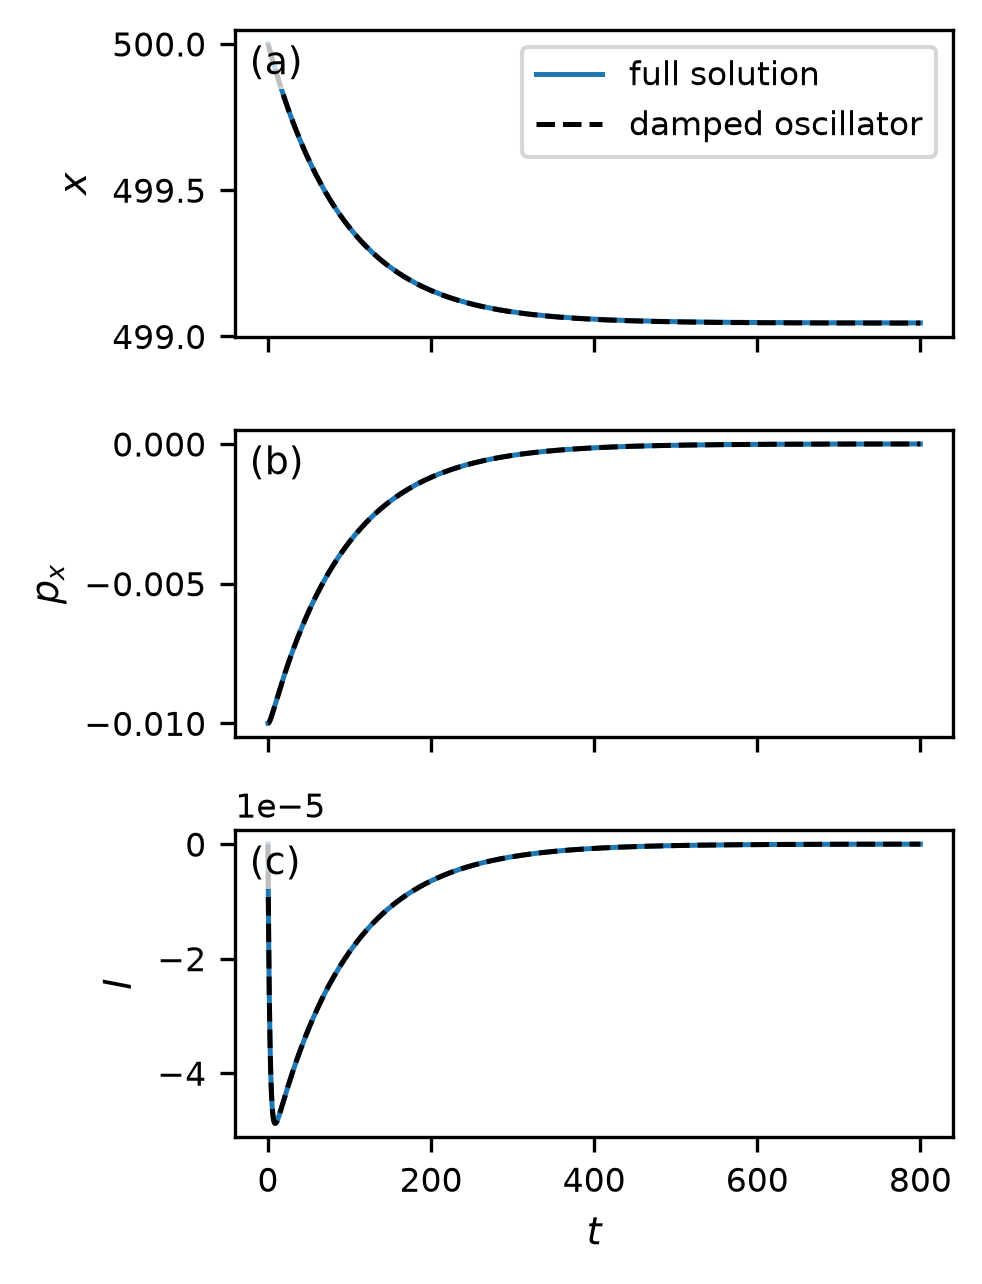

Q = 0.1557 (< 1/2: over-damped)
peak speed |p| = 0.010000  (reduced units)
total distance moved = 0.953967  (reduced units, d=1)


In [3]:
t0 = time.time()
B_normal = 2.e-2
x_n, p_n, I_n, F_n, K_n, Eb_n, Q_n = dynamics.verlet_integrate(
    x0, p0, l, B_normal, rho, dt, N_NORMAL, N_PRINT_NORMAL)
x_n, p_n, I_n = np.array(x_n), np.array(p_n), np.array(I_n)
t_n = N_PRINT_NORMAL * dt * np.arange(len(x_n))
print(f"ran {N_NORMAL:,} steps in {time.time()-t0:.2f}s, {len(x_n)} points recorded")

x_model_n, p_model_n, I_model_n = models.damped_oscillator(
    t_n, x0, p0, B_normal, rho, l)

fig = figures.plot_xpI(t_n, x_n, p_n, I_n, x_model_n, p_model_n, I_model_n,
                       save_path=fig_path('xpI_mu_normalB.jpg'))
plt.show()

Q_normal = models.quality_factor(l, x0, B_normal, rho)
print(f"Q = {Q_normal:.4f} (< 1/2: over-damped)")
print(f"peak speed |p| = {np.max(np.abs(p_n)):.6f}  (reduced units)")
print(f"total distance moved = {x0 - x_n.min():.6f}  (reduced units, d=1)")


## Figure: $x$, $p_x$, $I$ vs $t$ -- under-damped case ($Q>1/2$)

Paper: with a field fifteen times larger, $Q\simeq2.3>1/2$, and the same
damped-oscillator solution switches to its under-damped branch,
eq. (udsol): the bar oscillates around an equilibrium position, stopping
in about 0.002 s with a small initial amplitude. The overlay is again
dashed, and tracks the full simulation just as closely as it does on the
over-damped side -- the single analytic solution covers both. Together
with the previous cell this reproduces the paper's Fig. 2 (right panel:
`xpI_mu_largeB.jpg`).


ran 1,000,000 steps in 0.84s, 50000 points recorded


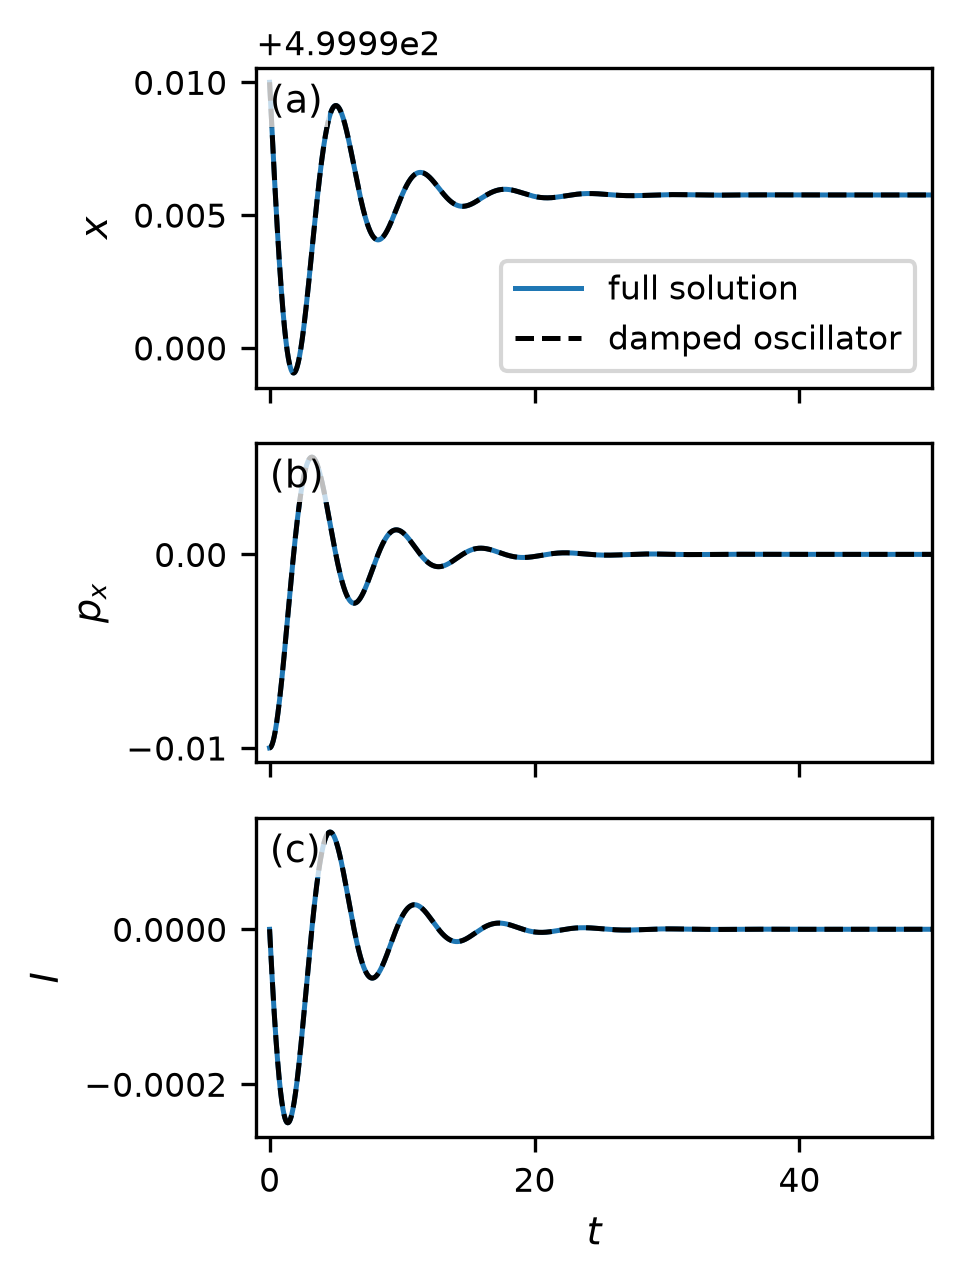

Q = 2.3359 (> 1/2: under-damped)


In [4]:
t0 = time.time()
B_large = 0.3
x_l, p_l, I_l, F_l, K_l, Eb_l, Q_l = dynamics.verlet_integrate(
    x0, p0, l, B_large, rho, dt, N_LARGE, N_PRINT_LARGE)
x_l, p_l, I_l = np.array(x_l), np.array(p_l), np.array(I_l)
t_l = N_PRINT_LARGE * dt * np.arange(len(x_l))
print(f"ran {N_LARGE:,} steps in {time.time()-t0:.2f}s, {len(x_l)} points recorded")

x_model_l, p_model_l, I_model_l = models.damped_oscillator(
    t_l, x0, p0, B_large, rho, l)

fig = figures.plot_xpI(t_l, x_l, p_l, I_l, x_model_l, p_model_l, I_model_l,
                       xlim=(-1, 50), save_path=fig_path('xpI_mu_largeB.jpg'))
plt.show()

Q_large = models.quality_factor(l, x0, B_large, rho)
print(f"Q = {Q_large:.4f} (> 1/2: under-damped)")


## Figure: self-inductance vs. Rosa/Grover

The self-inductance $L(x,l)$ derived in this work against the classical
closed-form expression of Rosa (1908)/Grover (2004), which assumes
$x,l\gg d$. Supplement: visually indistinguishable, and within $0.5\%$
already at $x=100d$ ($l/d=100$). The cell also prints the agreement at
$x=2d$, which the supplement does not quote. Reproduces the supplement's
self-inductance comparison figure (`rosa_grover.jpg`).

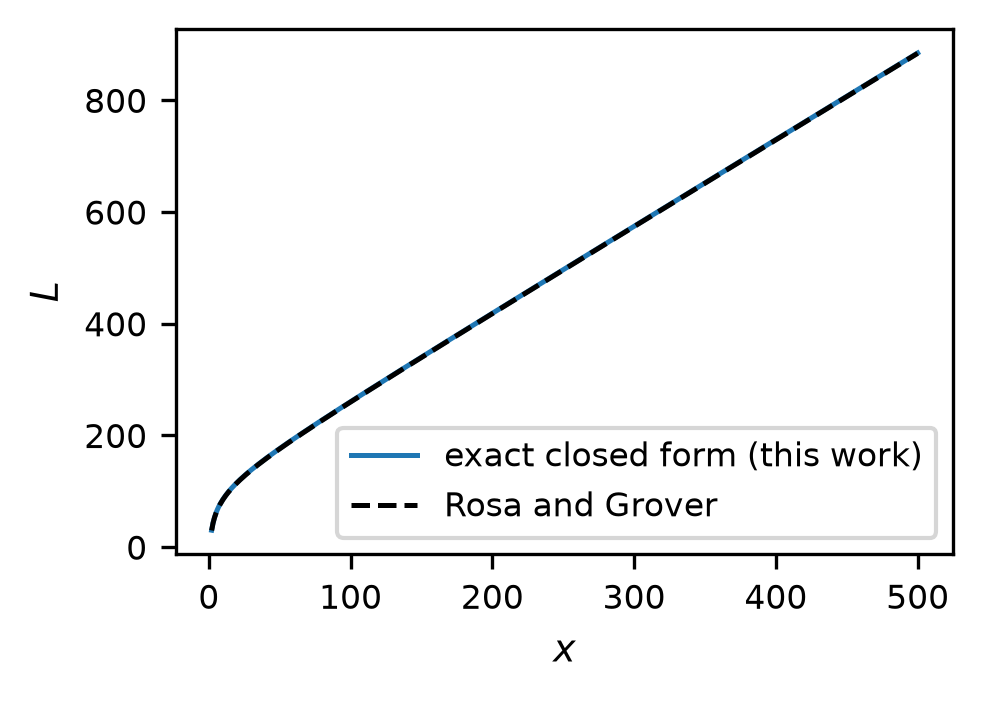

|1 - L_rosa/L| at x=100d:  0.195%   (supplement: <0.5%)
|1 - L_rosa/L| at x=2d:    1.595%   (additional check)
|1 - dLrosa/dL| at x=2d:   0.0770%   (additional check)


In [5]:
def rosa_inductance(mu, l, x, d):
    r = np.sqrt(x**2 + l**2)
    return (mu/np.pi)*(x*np.log(np.abs(2*x/d)) + l*np.log(np.abs(2*l/d))
              - 0.75*(x+l) - x*np.log(np.abs((r+x)/l)) + r - l
              - l*np.log(np.abs((r+l)/x)) + r - x)

def dL_rosa(mu, l, x, d):
    r = np.sqrt(x**2 + l**2)
    return (mu/np.pi)*(np.log(np.abs(2*x/d)) - np.log(np.abs((r+x)/l)) - 0.75
                        + x/r - l*x/(r*(r+l)) + l/x)

d = 1.0
x_arr = np.arange(2, 501)
L_eq = np.array([inductance.self_inductance(mu, d, l, xx) for xx in x_arr])
L_rosa_arr = rosa_inductance(mu, l, x_arr, d)
dL_eq = np.array([inductance.self_inductance_dx(mu, d, l, xx) for xx in x_arr])
dL_rosa_arr = dL_rosa(mu, l, x_arr, d)

fig = figures.plot_rosa_grover(x_arr, L_eq, L_rosa_arr,
                               save_path=fig_path('rosa_grover.jpg'))
plt.show()

ratio = L_rosa_arr / L_eq
i100 = np.argmin(np.abs(x_arr - 100))
i2 = np.argmin(np.abs(x_arr - 2))
print(f"|1 - L_rosa/L| at x=100d:  {abs(1-ratio[i100])*100:.3f}%   (supplement: <0.5%)")
print(f"|1 - L_rosa/L| at x=2d:    {abs(1-ratio[i2])*100:.3f}%   (additional check)")
print(f"|1 - dLrosa/dL| at x=2d:   {abs(1-dL_rosa_arr[i2]/dL_eq[i2])*100:.4f}%   (additional check)")


## Figure: self-inductance vs. its asymptotic form

$L(x,l)$ compared with its $x\to\infty$ linear asymptote. Paper: error
already below $3\%$ at $x=100d$. Reproduces the supplement's
self-inductance-vs-asymptote figure (`inductance.jpg`).

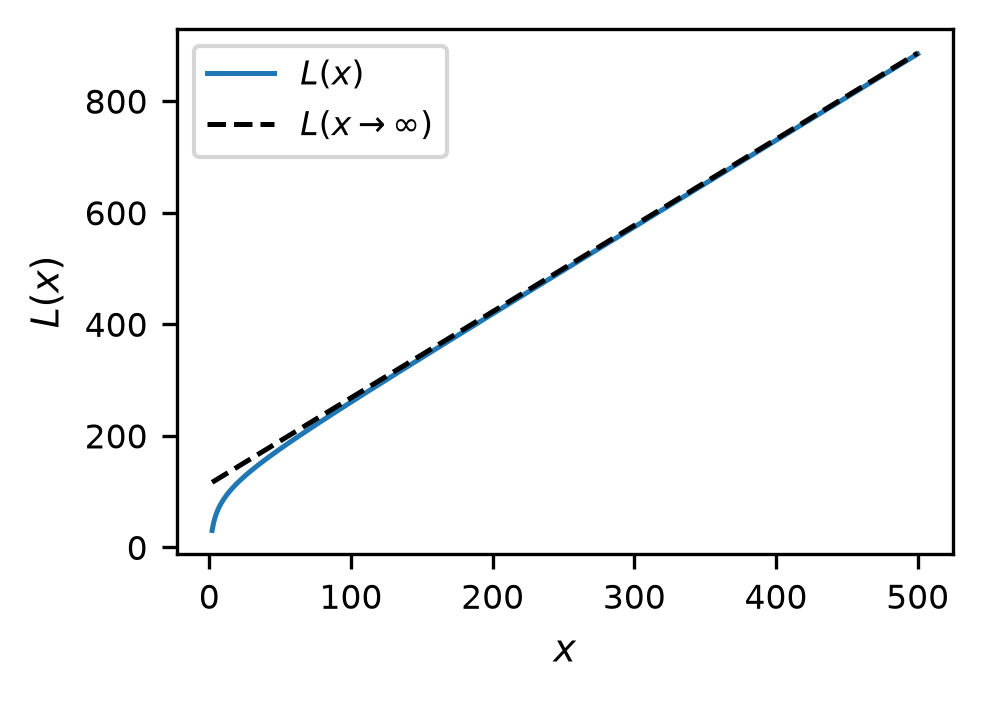

|L - L_asymp|/L at x=100d: 2.95%   (paper: <3%)


In [6]:
L_asymp_arr = np.array([inductance.self_inductance_asymp(mu, d, l, xx) for xx in x_arr])

fig = figures.plot_L_vs_asymptote(x_arr, L_eq, L_asymp_arr,
                                  save_path=fig_path('inductance.jpg'))
plt.show()

relerr_100d = abs(L_eq[i100] - L_asymp_arr[i100]) / L_eq[i100]
print(f"|L - L_asymp|/L at x=100d: {relerr_100d*100:.2f}%   (paper: <3%)")


## Figure: the effect of $\varepsilon$ on either side of the critical point

Everything above lives at $\varepsilon\lesssim3\times10^{-4}$, where the
$dL/dx$ terms are invisible and the parameter-free damped-oscillator
solution works. This section sweeps $\varepsilon$ up to $0.5$ and measures
the two things that appear once they are not.

$\varepsilon=L'I_m/(lB_0)=(L'/L(x_0))X_m$ is the fractional change of the
self-inductance over the free amplitude $X_m=|v_0|/\omega_0$ (eq.
`thresh`), set through the launch momentum by eq. `thresh`,
$|p_0|=\varepsilon\,lB_0\sqrt{L(x_0)}/L'$. Displacements are measured in
units of $X_m$, $\chi=(x-x_0)/X_m$, which is the rescaling of eqs.
(`chieq`)-(`rescaled`).

* **Non-isochronicity ($O(\varepsilon)$), above the critical point only.**
  The peak-to-peak spread of the instantaneous frequency, read off the zero
  crossings of $I(t)$ (`models.instantaneous_frequency`), is proportional to
  $\varepsilon$ with a coefficient that grows from $\simeq0.98$ at $Q=11.7$
  towards its dissipationless value as the damping weakens.
* **A shifted resting position, in both regimes.** The final $\chi_\infty$
  against $\varepsilon$, fitted to eq. `restlaw`,
  $\chi_\infty=-1/Q+c\varepsilon$, with the $\varepsilon$-independent term
  held at its predicted $-1/Q$ so that $c$ is the only measured number.
  The predicted slope is $c=1/4+(m/2\varepsilon)(1+Q^{-2})$: the rectified
  thrust plus the fall of $R$. Under-damped, $c\simeq0.73$ and the two
  contributions cancel at $\varepsilon^*=1/(cQ)$ (eq. `epsstar`), beyond
  which the bar comes to rest on the far side of where it was launched.
  Over-damped, $c$ is instead dominated by its $Q^{-2}$ term ($c=20.4$ at
  $Q=0.16$), almost all of it the fall of $R$ as the bar advances, so the bar simply stops short of
  the oscillator's prediction (eq. `eq:rest-od`; the split of $c$ into its thrust
  and $R$ parts, eq. `restlaw`, is checked in Notebook 2, B9-B10).

The last cell draws the paper's figure: two values of $\varepsilon$ at each
of two $Q$, one on each side of the critical point. Note that the two
regimes admit very different ranges of $\varepsilon$ -- over-damped the
excursion is $X_m/Q$, so $\varepsilon$ must stay small compared with $Q$.

Each run is integrated for $20/\gamma$, i.e. $20$ amplitude e-foldings;
the measured $\chi_\infty$ is converged in that window to better than
$10^{-8}$ relative, and quartering $\Delta t$ moves it by $\sim10^{-7}$
relative.

**Runtime note:** the full sweep is ~30M integration steps -- some tens of
seconds with `numba`, hours without it. The reduced default below uses five
$\varepsilon$ values instead of nine and two resistivities instead of three;
set `FULL_RESOLUTION = True` in the first cell for the paper's own sweep.


In [7]:
# --- the eps sweep: drift and frequency spread at each (eps, rho) ---
eps_scan = (np.array([0.02, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50])
            if FULL_RESOLUTION else np.array([0.02, 0.10, 0.20, 0.35, 0.50]))
rho_scan = ([(0.02, 'tab:blue'), (0.01, 'tab:green'), (0.005, 'tab:orange')]
            if FULL_RESOLUTION else [(0.02, 'tab:blue'), (0.01, 'tab:green')])
# Sec. "Beyond the RLC limit" uses its own, coarser step: the ring-downs
# here are 20/gamma long, 50x the span of the Sec. "Results" runs above,
# and chi_inf is converged to ~1e-7 relative at dt=1e-2 (quartering it
# moves nothing at the sixth digit).
B0_eps, N_TAU, n_print_eps, dt_eps = 0.03, 20, 10, 1.0e-2

w0_eps = models.omega0(l, x0, B0_eps)
T0_eps = 2 * np.pi / w0_eps
L_x0 = inductance.self_inductance(mu, 1.0, l, x0)
Lp_x0 = inductance.self_inductance_dx(mu, 1.0, l, x0)
print(f"omega_0 = {w0_eps:.6f}, T_0 = {T0_eps:.4f}, "
      f"|p0|/eps = {models.p0_from_epsilon(1.0, l, x0, B0_eps):.4f}, "
      f"X_m/eps = {models.free_amplitude(1.0, l, x0):.3f}, dt = {dt_eps:g}")
print(f"k = L'x0/L(x0) = {Lp_x0 * x0 / L_x0:.4f}, "
      f"eps/m = L'(x0+l)/L(x0) = {Lp_x0 * (x0 + l) / L_x0:.4f}")


def ring_down(eps, rho, n_tau=N_TAU):
    """Launch at the amplitude set by eps (eq. p0eps) and integrate until
    the bar has come to rest: n_tau amplitude e-foldings."""
    gam = models.gamma_exact(l, x0, rho)
    n_steps = int(n_tau / gam / dt_eps)
    p0_eps = -models.p0_from_epsilon(eps, l, x0, B0_eps)
    xe, pe, Ie, *_ = dynamics.verlet_integrate(
        x0, p0_eps, l, B0_eps, rho, dt_eps, n_steps, n_print_eps)
    return n_print_eps * dt_eps * np.arange(len(xe)), np.array(xe), np.array(Ie)


t0 = time.time()
scan = []
for rho_e, colour in rho_scan:
    Q_e = models.quality_factor(l, x0, B0_eps, rho_e)
    gam_e = models.gamma_exact(l, x0, rho_e)
    chi_inf, spread, w_end = [], [], []
    for eps in eps_scan:
        te, xe, Ie = ring_down(eps, rho_e)
        chi_inf.append((xe[-1] - x0) / models.free_amplitude(eps, l, x0))
        _, w_inst = models.instantaneous_frequency(te, Ie)
        spread.append((w_inst.max() - w_inst.min()) / w_inst.mean())
        wd_inf = np.sqrt(models.omega0(l, xe[-1], B0_eps)**2 - gam_e**2)
        w_end.append((w_inst[-1], wd_inf))
    chi_inf, spread = np.array(chi_inf), np.array(spread)
    c, eps_star = models.fit_drift_linear(eps_scan, chi_inf, Q_e)
    resid = chi_inf - (-1 / Q_e + c * eps_scan)

    print(f"\nrho = {rho_e}:  Q = {Q_e:.3f},  1/Q = {1/Q_e:.5f},  "
          f"c = {c:.4f},  eps* = {eps_star:.4f}  "
          f"(max fit residual {np.abs(resid).max():.1e})")
    print(f"  {'eps':>6} {'chi_inf':>10} {'dx/x0':>10} {'spread':>8} "
          f"{'spread/eps':>11} {'w_final':>9} {'w_d(x_inf)':>11}")
    for eps, ci, sp, (we, wd) in zip(eps_scan, chi_inf, spread, w_end):
        dx = ci * models.free_amplitude(eps, l, x0) / x0
        print(f"  {eps:6.2f} {ci:10.5f} {dx:10.5f} {sp:8.4f} {sp / eps:11.4f} "
              f"{we:9.5f} {wd:11.5f}")
    scan.append((rho_e, Q_e, eps_scan, chi_inf, c, eps_star, colour))
print(f"\nswept {len(rho_scan) * len(eps_scan)} ring-downs in {time.time() - t0:.1f}s")


omega_0 = 0.100867, T_0 = 62.2916, |p0|/eps = 57.6167, X_m/eps = 571.214, dt = 0.01
k = L'x0/L(x0) = 0.8753, eps/m = L'(x0+l)/L(x0) = 1.0504



rho = 0.02:  Q = 11.680,  1/Q = 0.08562,  c = 0.7332,  eps* = 0.1168  (max fit residual 1.8e-04)
     eps    chi_inf      dx/x0   spread  spread/eps   w_final  w_d(x_inf)
    0.02   -0.07102   -0.00162   0.0195      0.9749   0.10085     0.10085
    0.05   -0.04909   -0.00280   0.0488      0.9753   0.10090     0.10090
    0.10   -0.01248   -0.00143   0.0976      0.9761   0.10084     0.10084
    0.15    0.02420    0.00415   0.1465      0.9768   0.10059     0.10059
    0.20    0.06093    0.01392   0.1955      0.9774   0.10017     0.10017
    0.25    0.09767    0.02790   0.2445      0.9779   0.09956     0.09956
    0.30    0.13441    0.04607   0.2935      0.9782   0.09880     0.09880
    0.40    0.20782    0.09497   0.3912      0.9779   0.09682     0.09682
    0.50    0.28099    0.16051   0.4879      0.9757   0.09435     0.09435



rho = 0.01:  Q = 23.359,  1/Q = 0.04281,  c = 0.7263,  eps* = 0.0589  (max fit residual 6.7e-04)
     eps    chi_inf      dx/x0   spread  spread/eps   w_final  w_d(x_inf)
    0.02   -0.02827   -0.00065   0.0223      1.1135   0.10087     0.10087
    0.05   -0.00644   -0.00037   0.0557      1.1139   0.10086     0.10086
    0.10    0.02996    0.00342   0.1115      1.1152   0.10069     0.10069
    0.15    0.06637    0.01137   0.1676      1.1175   0.10035     0.10035
    0.20    0.10277    0.02348   0.2241      1.1206   0.09982     0.09982
    0.25    0.13913    0.03974   0.2811      1.1245   0.09913     0.09913
    0.30    0.17543    0.06012   0.3387      1.1291   0.09829     0.09829
    0.40    0.24777    0.11323   0.4560      1.1400   0.09619     0.09619
    0.50    0.31967    0.18260   0.5761      1.1523   0.09364     0.09364



rho = 0.005:  Q = 46.719,  1/Q = 0.02140,  c = 0.7235,  eps* = 0.0296  (max fit residual 9.8e-04)
     eps    chi_inf      dx/x0   spread  spread/eps   w_final  w_d(x_inf)
    0.02   -0.00688   -0.00016   0.0238      1.1906   0.10087     0.10087
    0.05    0.01492    0.00085   0.0596      1.1912   0.10082     0.10082
    0.10    0.05124    0.00585   0.1193      1.1934   0.10060     0.10060
    0.15    0.08755    0.01500   0.1796      1.1972   0.10021     0.10021
    0.20    0.12381    0.02829   0.2405      1.2025   0.09964     0.09964
    0.25    0.16001    0.04570   0.3023      1.2092   0.09890     0.09890
    0.30    0.19612    0.06722   0.3652      1.2174   0.09802     0.09802
    0.40    0.26802    0.12248   0.4950      1.2374   0.09585     0.09585
    0.50    0.33938    0.19386   0.6308      1.2615   0.09326     0.09326

swept 27 ring-downs in 25.3s


rho =  1.50 (Q =   0.156), eps = 0.002:  X_m =    1.14  x_end =  492.76  (oscillator  492.71,   0.6% short)
rho =  1.50 (Q =   0.156), eps = 0.080:  X_m =   45.70  x_end =  269.93  (oscillator  208.52,  21.1% short)
rho =  0.02 (Q =  11.680), eps = 0.002:  X_m =    1.14  x_end =  499.91  (oscillator  499.90,   1.7% short)


rho =  0.02 (Q =  11.680), eps = 0.400:  X_m =  228.49  x_end =  546.37  (oscillator  480.83, 341.9% short)


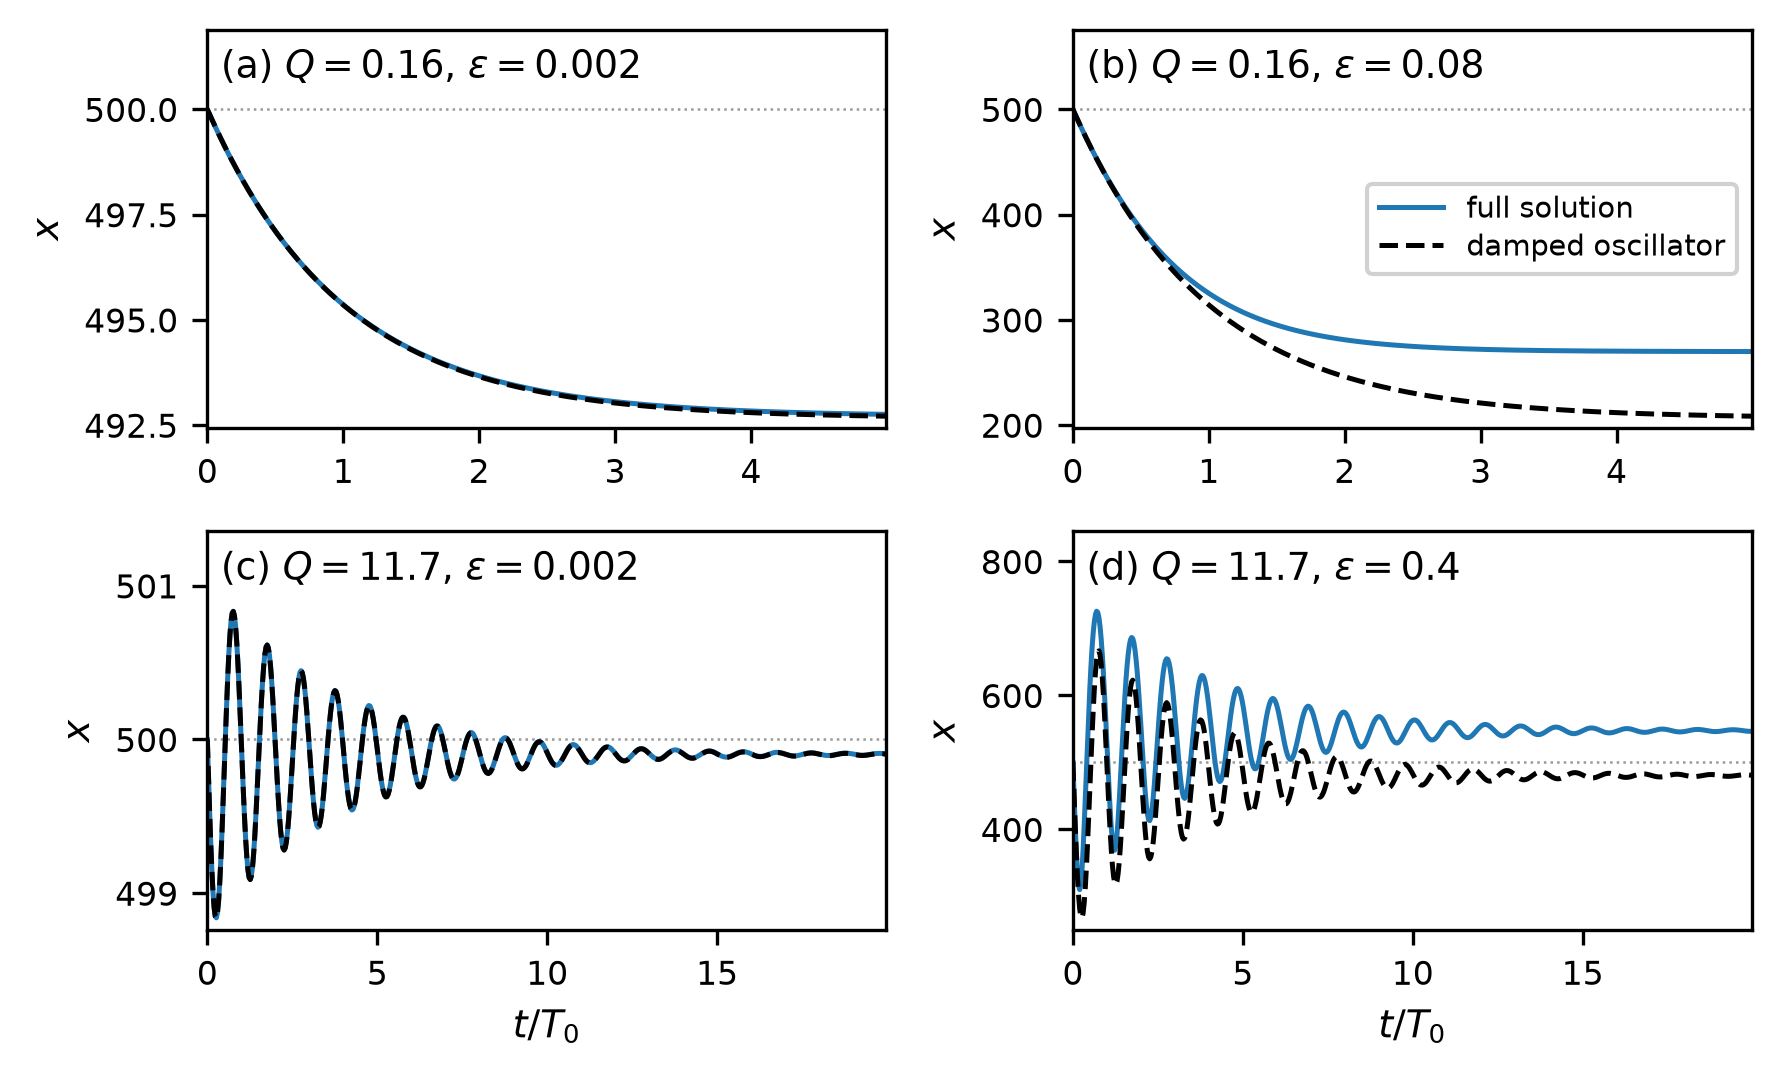

In [8]:
# --- the figure: x(t) at two eps on either side of the critical point ---
# rows of the figure: (rho, (small eps, large eps), periods to show)
# the small eps is set by the over-damped row: there the oscillator's own
# displacement is only X_m/Q while the eps correction is c*eps*X_m with
# c ~ 20, so the two are comparable already at eps ~ 0.02.
rows_eps = [(1.50, (0.002, 0.08), 5.0),    # over-damped,  Q = 0.16
            (0.02, (0.002, 0.40), 20.0)]   # under-damped, Q = 11.7
panels = []
for rho_r, eps_pair, n_per in rows_eps:
    Q_r = models.quality_factor(l, x0, B0_eps, rho_r)
    for eps in eps_pair:
        p0_eps = -models.p0_from_epsilon(eps, l, x0, B0_eps)
        n_steps = int(n_per * T0_eps / dt_eps)
        n_pr = max(1, n_steps // 600)
        xt, pt, It, *_ = dynamics.verlet_integrate(
            x0, p0_eps, l, B0_eps, rho_r, dt_eps, n_steps, n_pr)
        tt = n_pr * dt_eps * np.arange(len(xt))
        x_osc, _, _ = models.damped_oscillator(tt, x0, p0_eps, B0_eps, rho_r, l)
        xt = np.array(xt)
        fmt = f"{Q_r:.2f}" if Q_r < 1 else f"{Q_r:.1f}"
        panels.append((rf"$Q={fmt}$, $\varepsilon={eps:g}$", tt / T0_eps, xt, x_osc))
        print(f"rho = {rho_r:5.2f} (Q = {Q_r:7.3f}), eps = {eps:.3f}:  "
              f"X_m = {models.free_amplitude(eps, l, x0):7.2f}  "
              f"x_end = {xt[-1]:7.2f}  (oscillator {x_osc[-1]:7.2f}, "
              f"{100*(1 - (xt[-1]-x0)/(x_osc[-1]-x0)):5.1f}% short)")

fig = figures.plot_position_vs_eps(panels, x0,
                                   save_path=fig_path('position_vs_eps.jpg'))
plt.show()


## Beyond the paper's parameter sets

Everything above uses the paper's own $(B_0, \rho)$ values. The cell
below runs a single trajectory at parameters of your choosing --
change `B0_custom`, `rho_custom`, `x0_custom` or `p0_custom` and re-run.


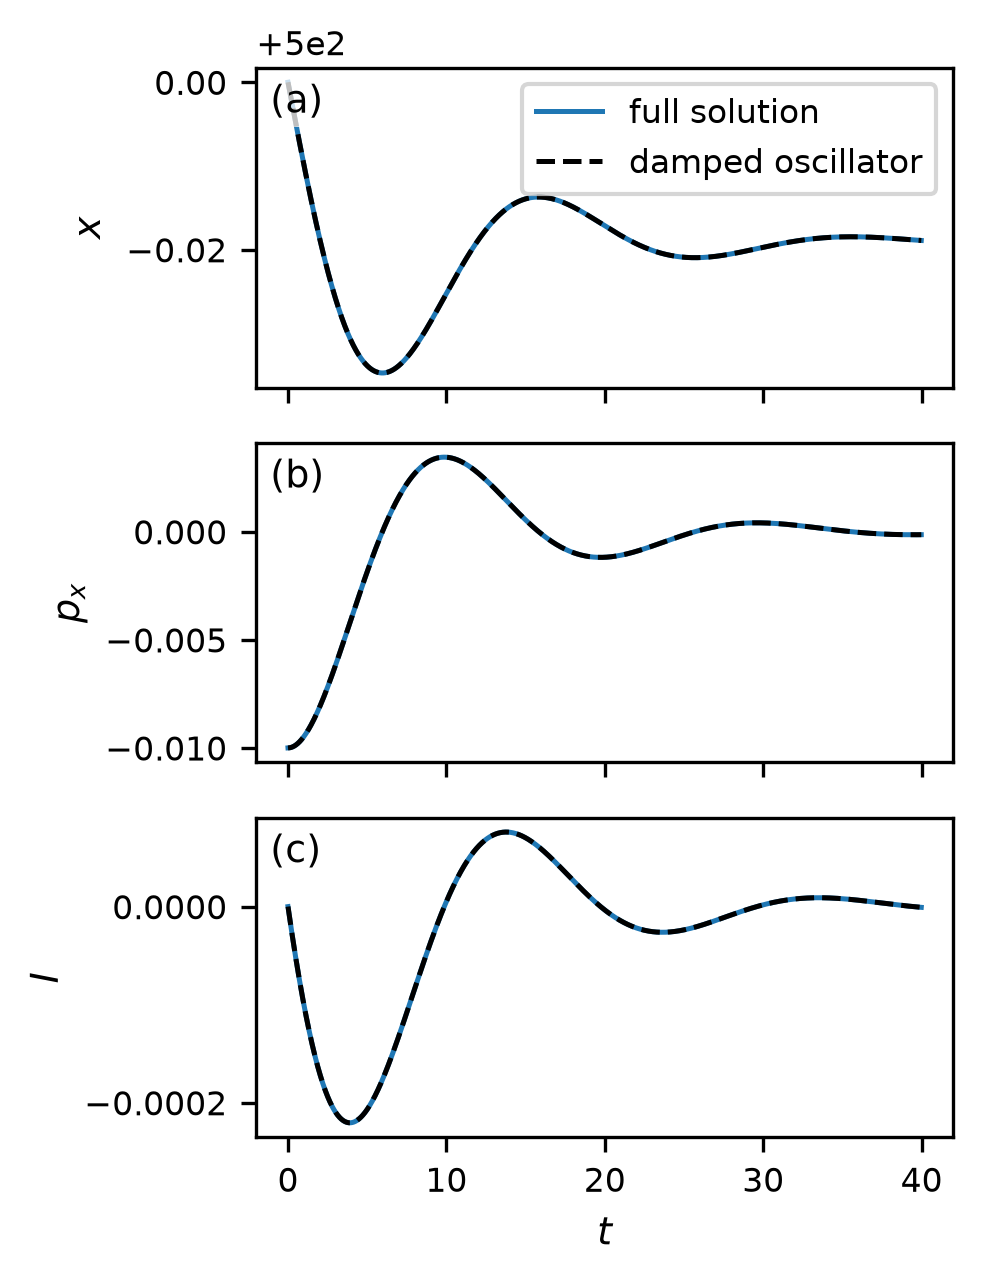

Q = 1.5573: under-damped. The overlay switches branch at Q = 1/2,
so it follows the simulation on either side; try values both sides of it.


In [9]:
B0_custom = 0.1
rho_custom = 0.5
x0_custom = 500.0
p0_custom = -1.e-2
n_steps_custom = 200_000

xc, pc, Ic, Fc, Kc, Ebc, Qc = dynamics.verlet_integrate(
    x0_custom, p0_custom, l, B0_custom, rho_custom, dt, n_steps_custom, 100)
xc, pc, Ic = np.array(xc), np.array(pc), np.array(Ic)
tc = 100 * dt * np.arange(len(xc))

x_model_c, p_model_c, I_model_c = models.damped_oscillator(
    tc, x0_custom, p0_custom, B0_custom, rho_custom, l)

fig = figures.plot_xpI(tc, xc, pc, Ic, x_model_c, p_model_c, I_model_c)
plt.show()

Q_custom = models.quality_factor(l, x0_custom, B0_custom, rho_custom)
regime = "under-damped" if Q_custom > 0.5 else "over-damped"
print(f"Q = {Q_custom:.4f}: {regime}. The overlay switches branch at Q = 1/2,")
print(f"so it follows the simulation on either side; try values both sides of it.")
